# Лабораторная работа №6. Лемматизация и векторизация текстов
**Годуленко Матвей, ЭТ-213**

Цель: очистить отзывы о фильмах, привести слова к начальной форме, построить мешок слов и TF-IDF и сравнить документы. Выполнены задания 1–5 и бонус 6.1. Все ячейки запускаются сверху вниз; имена переменных записаны латиницей.

В условии есть опечатки: используем `min_df=2`, `max_features=200` и список русских стоп-слов, поскольку sklearn не принимает `min_freq`, `max_feature` и `stop_words='russian'`. Папка называется `lab6`, в соответствии с номером работы; упоминания `lab7` в оформлении считаем опечаткой.

In [1]:
import re
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymorphy3
from nltk.stem.snowball import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_colwidth', 180)

try:
    df = pd.read_csv('data/reviews.csv', encoding='utf-8')
except UnicodeDecodeError:
    df = pd.read_csv('data/reviews.csv', encoding='cp1251')
print('Размер таблицы:', df.shape)
print('Пропуски:', df.isna().sum().to_dict())
assert not df['text'].isna().any()
assert df['text'].str.strip().ne('').all()
print('Дубликаты id:', df['id'].duplicated().sum())
print('Диапазон оценок:', df['rating'].min(), '—', df['rating'].max())
display(df.head())

Matplotlib is building the font cache; this may take a moment.


Размер таблицы: (25, 3)
Пропуски: {'id': 0, 'text': 0, 'rating': 0}
Дубликаты id: 0
Диапазон оценок: 1 — 10


,id,text,rating
0,1,"Отличный фильм! Сюжет захватывает с первых минут, актёры играют прекрасно.",9
1,2,"Скучно и затянуто, еле досмотрел до конца. Больше не буду смотреть такого режиссёра.",2
2,3,Превосходная игра актёров! Особенно главный герой — просто находка для этого фильма.,10
3,4,"УЖАСНЫЙ СЦЕНАРИЙ, ничего не понятно. Потратил 2 часа зря.",1
4,5,Замечательная режиссура и красивые пейзажи. Смотрел на https://example.com/trailer — трейлер не обманул!,8


Загружены **25 отзывов**. В text нет пропусков и пустых строк, оценки находятся в диапазоне 1–10. id — номер отзыва, rating — оценка, text — текст. rating не участвует в построении текстовых векторов.

## Задание 1. Очистка и лемматизация

In [2]:
morph = pymorphy3.MorphAnalyzer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'<[^>]*>', ' ', text)
    text = re.sub(r'#\w+', ' ', text)
    text = re.sub(r'[^а-яё\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

def lemmatize_text(text):
    return ' '.join(morph.parse(word)[0].normal_form for word in text.split())

df['text_clean'] = df['text'].map(clean_text)
df['text_prepared'] = df['text_clean'].map(lemmatize_text)
print('Примеры очистки:')
display(df.loc[df['id'].isin([4, 5, 6, 10, 18]), ['id', 'text', 'text_clean']])
print('Примеры лемматизации:')
display(df[['id', 'text_clean', 'text_prepared']].head(5))

Примеры очистки:


,id,text,text_clean
3,4,"УЖАСНЫЙ СЦЕНАРИЙ, ничего не понятно. Потратил 2 часа зря.",ужасный сценарий ничего не понятно потратил часа зря
4,5,Замечательная режиссура и красивые пейзажи. Смотрел на https://example.com/trailer — трейлер не обманул!,замечательная режиссура и красивые пейзажи смотрел на трейлер не обманул
5,6,"Плохо, очень плохо. Не рекомендую. #плохойфильм",плохо очень плохо не рекомендую
9,10,"Слабый фильм, сюжет предсказуем с первых минут. <b>Очень</b> жаль потраченного времени.",слабый фильм сюжет предсказуем с первых минут очень жаль потраченного времени
17,18,"Так себе. Можно посмотреть один раз, второй раз — уже неинтересно. #кино #отзыв",так себе можно посмотреть один раз второй раз уже неинтересно


Примеры лемматизации:


,id,text_clean,text_prepared
0,1,отличный фильм сюжет захватывает с первых минут актёры играют прекрасно,отличный фильм сюжет захватывать с первый минута актёр играть прекрасно
1,2,скучно и затянуто еле досмотрел до конца больше не буду смотреть такого режиссёра,скучно и затянутый еле досмотреть до конец большой не быть смотреть такой режиссёр
2,3,превосходная игра актёров особенно главный герой просто находка для этого фильма,превосходный игра актёр особенно главный герой просто находка для это фильм
3,4,ужасный сценарий ничего не понятно потратил часа зря,ужасный сценарий ничего не понятно потратить час зря
4,5,замечательная режиссура и красивые пейзажи смотрел на трейлер не обманул,замечательный режиссура и красивый пейзаж смотреть на трейлер не обмануть


In [3]:
raw_words = re.findall(r'[а-яё]+', ' '.join(df['text']).lower())
clean_words = ' '.join(df['text_clean']).split()
lemma_words = ' '.join(df['text_prepared']).split()
vocab_table = pd.DataFrame({
    'Этап': ['Русские слова в исходном тексте', 'После очистки', 'После лемматизации'],
    'Уникальные слова': [len(set(raw_words)), len(set(clean_words)), len(set(lemma_words))],
    'Всего слов': [len(raw_words), len(clean_words), len(lemma_words)]
})
display(vocab_table)
print('Сокращение словаря после лемматизации:',
      round((1 - len(set(lemma_words)) / len(set(clean_words))) * 100, 1), '%')

,Этап,Уникальные слова,Всего слов
0,Русские слова в исходном тексте,188,269
1,После очистки,186,265
2,После лемматизации,161,265


Сокращение словаря после лемматизации: 13.4 %


Очистка убирает ссылки, HTML-разметку, хэштег целиком, цифры и пунктуацию; текст приводится к нижнему регистру. Например, удаляется «#плохойфильм», а содержимое тега `<b>Очень</b>` сохраняется. Дефисы заменяются пробелами, поэтому «что-то» становится двумя токенами.

Число уникальных русских слов: **188 → 186 → 161**. Сравнение со словарём после очистки отделяет эффект лемматизации от удаления шума; уменьшение составляет **13.4%**. Выбрана лемматизация: формы «фильм», «фильмов», «фильма» объединяются в понятное слово «фильм». В отличие от стемминга, полученные формы обычно можно прочитать. Берётся наиболее вероятный разбор pymorphy3 без контекста, поэтому неоднозначные слова могут разбираться неверно. Буква ё сохраняется.

## Задание 2. Мешок слов и N-граммы

In [4]:
bow = CountVectorizer()
X_bow = bow.fit_transform(df['text_prepared'])
bow_ngrams = CountVectorizer(ngram_range=(1, 2))
X_ngrams = bow_ngrams.fit_transform(df['text_prepared'])
bow_filtered = CountVectorizer(min_df=2, max_df=0.9)
X_filtered = bow_filtered.fit_transform(df['text_prepared'])
ngrams_filtered = CountVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9)
X_ngrams_filtered = ngrams_filtered.fit_transform(df['text_prepared'])
shape_table = pd.DataFrame({
    'Вариант': ['Униграммы', 'Униграммы + биграммы', 'Униграммы с фильтрами', 'Униграммы + биграммы с фильтрами'],
    'Документов': [X_bow.shape[0], X_ngrams.shape[0], X_filtered.shape[0], X_ngrams_filtered.shape[0]],
    'Признаков': [X_bow.shape[1], X_ngrams.shape[1], X_filtered.shape[1], X_ngrams_filtered.shape[1]]
})
display(shape_table)
print('Несколько биграмм:', [word for word in bow_ngrams.get_feature_names_out() if ' ' in word][:15])
print('Словарь после фильтров:', bow_filtered.get_feature_names_out())
print('Слова, встречающиеся более чем в 90% документов:',
      bow.get_feature_names_out()[np.asarray((X_bow > 0).sum(axis=0)).ravel() > 0.9 * len(df)])

,Вариант,Документов,Признаков
0,Униграммы,25,156
1,Униграммы + биграммы,25,372
2,Униграммы с фильтрами,25,44
3,Униграммы + биграммы с фильтрами,25,49


Несколько биграмм: ['актёр играть', 'актёр музыка', 'актёр но', 'актёр особенно', 'актёр подробный', 'актёрский состав', 'без восторг', 'больший от', 'большой не', 'бред где', 'бы сделать', 'быть бы', 'быть но', 'быть смотреть', 'быть трейлер']
Словарь после фильтров: ['актёр' 'быть' 'весь' 'время' 'всё' 'второй' 'год' 'для' 'до' 'зря'
 'игра' 'из' 'интересный' 'кто' 'минута' 'можно' 'мой' 'на' 'не' 'ни' 'но'
 'один' 'ожидать' 'особенно' 'очень' 'первый' 'по' 'понравиться'
 'потратить' 'просто' 'раз' 'режиссура' 'рекомендовать' 'сильный' 'слабый'
 'смотреть' 'сюжет' 'такой' 'то' 'трейлер' 'фильм' 'хороший' 'что'
 'шедевр']
Слова, встречающиеся более чем в 90% документов: []


В мешке слов строка соответствует отзыву, столбец — слову, значение — числу появлений. Униграммы дают **156 признаков**, добавление биграмм увеличивает число до **372**, поскольку соседние пары слов становятся отдельными признаками.

`min_df=2` оставляет признаки, встретившиеся хотя бы в двух разных документах, а не просто два раза в одном отзыве. `max_df=0.9` удаляет признаки более чем из 90% документов, то есть из 23 и более отзывов; в этом корпусе таких униграмм нет. После фильтров остаётся **44** и **49** признаков. CountVectorizer по умолчанию игнорирует односимвольные токены, поэтому его словарь отличается от подсчёта всех слов через split().

## Задание 3. TF-IDF и стоп-слова

In [5]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=200)
X_tfidf = tfidf.fit_transform(df['text_prepared'])

# Список NLTK сохранён в проекте: скачивание при запуске не требуется.
stop_raw = Path('data/russian_stopwords.txt').read_text(encoding='utf-8').split()
# Приводим стоп-слова к той же форме, что и тексты.
stop_words = sorted({morph.parse(word)[0].normal_form for word in stop_raw})
tfidf_stop = TfidfVectorizer(ngram_range=(1, 2), max_features=200, stop_words=stop_words)
X_tfidf_stop = tfidf_stop.fit_transform(df['text_prepared'])
print('Без стоп-слов:', X_tfidf.shape)
print('Со стоп-словами:', X_tfidf_stop.shape)
print('Лемматизированных стоп-слов:', len(stop_words))

def get_top_words(matrix, vectorizer):
    words = vectorizer.get_feature_names_out()
    result = []
    for i in range(matrix.shape[0]):
        row = matrix.getrow(i)
        order = np.argsort(-row.data, kind='stable')[:3]
        top = [f'{words[row.indices[j]]}: {row.data[j]:.3f}' for j in order]
        result.append('; '.join(top))
    return result

top_table = pd.DataFrame({
    'id': df['id'],
    'Топ-3 без удаления стоп-слов': get_top_words(X_tfidf, tfidf),
    'Топ-3 после удаления стоп-слов': get_top_words(X_tfidf_stop, tfidf_stop)
})
display(top_table)

Без стоп-слов: (25, 200)
Со стоп-словами: (25, 200)
Лемматизированных стоп-слов: 114


,id,Топ-3 без удаления стоп-слов,Топ-3 после удаления стоп-слов
0,1,прекрасно: 0.362; отличный фильм: 0.362; сюжет захватывать: 0.362,захватывать: 0.281; играть: 0.281; прекрасно: 0.281
1,2,скучно: 0.362; режиссёр: 0.362; скучно затянутый: 0.362,скучно: 0.284; затянутый: 0.284; еле: 0.284
2,3,превосходный: 0.365; превосходный игра: 0.365; просто находка: 0.365,превосходный: 0.292; главный: 0.292; герой: 0.292
3,4,ужасный: 0.306; сценарий: 0.306; понятно: 0.306,ужасный: 0.310; сценарий: 0.310; понятно: 0.310
4,5,пейзаж: 0.359; режиссура красивый: 0.359; пейзаж смотреть: 0.359,замечательный: 0.338; красивый: 0.338; замечательный режиссура: 0.338
5,6,плохо: 0.678; плохо очень: 0.339; очень плохо: 0.339,плохо: 0.858; рекомендовать: 0.380; очень: 0.346
6,7,попадание: 0.338; хороший фильм: 0.338; фильм год: 0.338,попадание: 0.391; фильм год: 0.391; год обязательно: 0.391
7,8,разочарование: 0.429; состав: 0.429; разочарование ожидать: 0.429,разочарование: 0.358; больший: 0.358; актёрский: 0.358
8,9,раз: 0.503; пересматривать: 0.284; три: 0.284,великолепно: 0.500; каждый: 0.500; великолепно пересматривать: 0.500
9,10,предсказуемый: 0.279; слабый фильм: 0.279; сюжет предсказуемый: 0.279,предсказуемый: 0.269; жаль: 0.269; слабый фильм: 0.269


In [6]:
tfidf_raw = TfidfVectorizer(ngram_range=(1, 2), max_features=200, norm=None)
X_tfidf_raw = tfidf_raw.fit_transform(df['text_prepared'])
display(pd.DataFrame({
    'id': df['id'].head(5),
    'L2-норма, обычный вариант': np.sqrt(X_tfidf[:5].multiply(X_tfidf[:5]).sum(axis=1)).A1,
    'L2-норма, norm=None': np.sqrt(X_tfidf_raw[:5].multiply(X_tfidf_raw[:5]).sum(axis=1)).A1
}))
print('Топ-3 первого отзыва при norm=None:', get_top_words(X_tfidf_raw, tfidf_raw)[0])

,id,"L2-норма, обычный вариант","L2-норма, norm=None"
0,1,1.0,9.855585
1,2,1.0,9.848664
2,3,1.0,9.767163
3,4,1.0,11.664892
4,5,1.0,9.936362


Топ-3 первого отзыва при norm=None: прекрасно: 3.565; отличный фильм: 3.565; сюжет захватывать: 3.565


TF-IDF увеличивает вес признака, если он часто встречается в конкретном документе и редко — в корпусе. Ограничение 200 выбирает не более 200 признаков по суммарной частоте до расчёта весов; это не выбор 200 самых больших TF-IDF. Матрицы имеют размеры **(25, 200)** и **(25, 200)**.

Например, у отзыва id=1 топ без удаления стоп-слов: **прекрасно, отличный фильм, сюжет захватывать**; после удаления: **захватывать, играть, прекрасно**. В таблице приведены все 25 отзывов. После удаления служебных слов чаще выделяются смысловые слова и сочетания, но меняется также состав биграмм. После удаления стоп-слов соседями могут стать слова, между которыми раньше стояло служебное слово.

Нормализация L2 делит веса строки на её длину: сумма квадратов весов становится равной 1. `norm=None` даёт более крупные числа; порядок признаков внутри одного документа сохраняется, поскольку нормализация умножает всю строку на один коэффициент. При равенстве весов топ-3 не единственен.

**Ограничение:** стандартные русские стоп-слова включают отрицания («не», «ни», «нет»). Это допустимо для демонстрации, но может потерять смысл отрицательных отзывов; для анализа тональности отрицания следует сохранить или отдельно кодировать. В этой работе модель тональности не обучается.

## Задание 4. Разведочный анализ

### 4.1. Частоты слов

,Частота
не,10
фильм,7
смотреть,7
но,7
актёр,5
и,5
в,5
то,5
быть,4
на,4


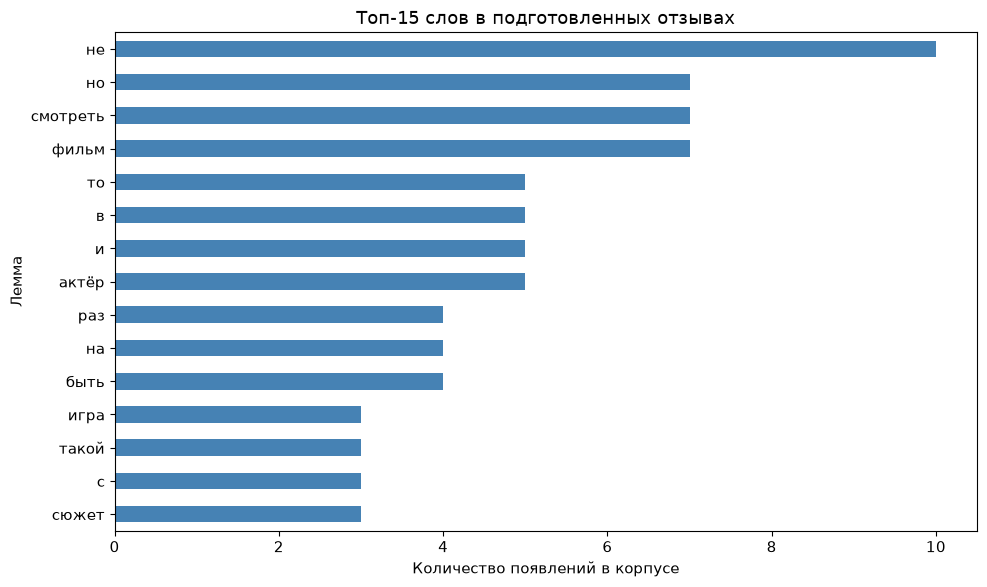

In [7]:
word_counts = Counter(' '.join(df['text_prepared']).split())
top15 = pd.Series(dict(word_counts.most_common(15)), name='Частота')
display(top15.to_frame())
fig, ax = plt.subplots(figsize=(10, 6))
top15.sort_values().plot.barh(ax=ax, color='steelblue')
ax.set_title('Топ-15 слов в подготовленных отзывах')
ax.set_xlabel('Количество появлений в корпусе')
ax.set_ylabel('Лемма')
plt.tight_layout()
plt.show()

Самое частое слово — **«не» (10 появлений)**. Здесь стоп-слова намеренно сохранены, как требует подсчёт частот в text_prepared; служебные слова могут занимать верхние места. Частота отражает повторяемость, а не обязательно смысловую важность — для этого выше рассмотрен TF-IDF. Все токены, включая односимвольные, подсчитаны через split().

### 4.2. Длины документов

,Слов в отзыве
min,5.0
max,17.0
mean,10.6
median,10.0


Границы по IQR: 8.5 12.5
id отзывов-выбросов: [2, 4, 6, 8, 16, 25]


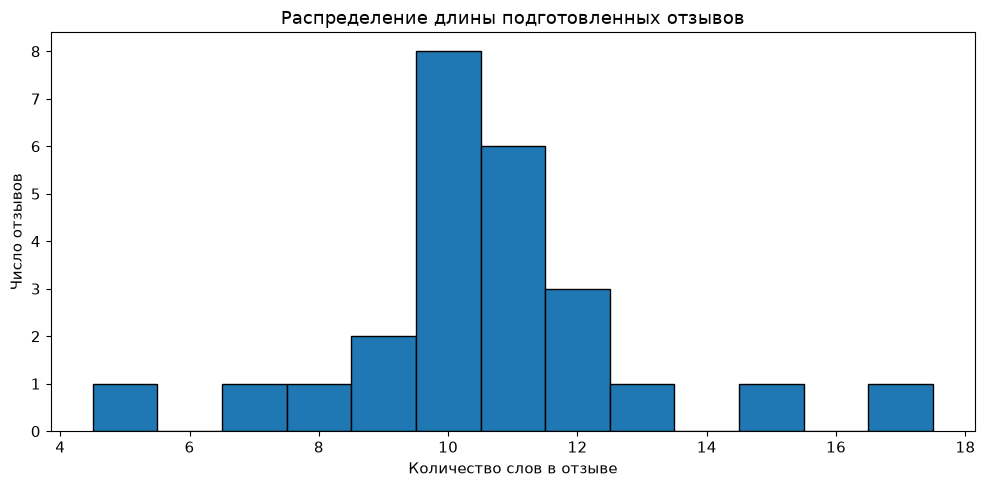

In [8]:
df['length_words'] = df['text_prepared'].str.split().str.len()
length_stats = df['length_words'].agg(['min', 'max', 'mean', 'median'])
display(length_stats.to_frame('Слов в отзыве'))
q1, q3 = df['length_words'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
length_outliers = df[(df['length_words'] < lower) | (df['length_words'] > upper)]
print('Границы по IQR:', lower, upper)
print('id отзывов-выбросов:', length_outliers['id'].tolist())
fig, ax = plt.subplots()
ax.hist(df['length_words'], bins=np.arange(df['length_words'].min() - 0.5, df['length_words'].max() + 1.5), edgecolor='black')
ax.set_title('Распределение длины подготовленных отзывов')
ax.set_xlabel('Количество слов в отзыве')
ax.set_ylabel('Число отзывов')
plt.tight_layout()
plt.show()

Длина после очистки и лемматизации: минимум **5**, максимум **17**, среднее **10.60**, медиана **10.0** слов. Для воспроизводимого решения о выбросах применено правило 1,5 IQR; id за границами: **[2, 4, 6, 8, 16, 25]**. Короткие отзывы не являются ошибками сами по себе. Это маленький корпус, поэтому вывод нельзя автоматически переносить на все отзывы о фильмах.

### 4.3. Косинусное сходство

id,1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
id,,,,,,,,,,,,,,,,,,,,,
1,1.00,0.00,0.07,0.00,0.00,0.00,0.04,0.00,0.0,0.32,...,0.03,0.04,0.00,0.00,0.00,0.00,0.03,0.00,0.04,0.06
2,0.00,1.00,0.00,0.00,0.04,0.00,0.04,0.00,0.0,0.00,...,0.00,0.00,0.00,0.04,0.04,0.00,0.00,0.04,0.00,0.00
3,0.07,0.00,1.00,0.00,0.00,0.00,0.04,0.00,0.0,0.03,...,0.03,0.16,0.00,0.00,0.00,0.00,0.03,0.00,0.12,0.00
4,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.0,0.05,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
5,0.00,0.04,0.00,0.00,1.00,0.00,0.05,0.00,0.0,0.00,...,0.00,0.08,0.00,0.04,0.04,0.00,0.00,0.31,0.00,0.00
6,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.0,0.07,...,0.08,0.00,0.00,0.00,0.00,0.00,0.10,0.00,0.00,0.00
7,0.04,0.04,0.04,0.00,0.05,0.00,1.00,0.00,0.0,0.04,...,0.04,0.00,0.00,0.15,0.05,0.00,0.04,0.05,0.00,0.00
8,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.0,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.09
9,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.0,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


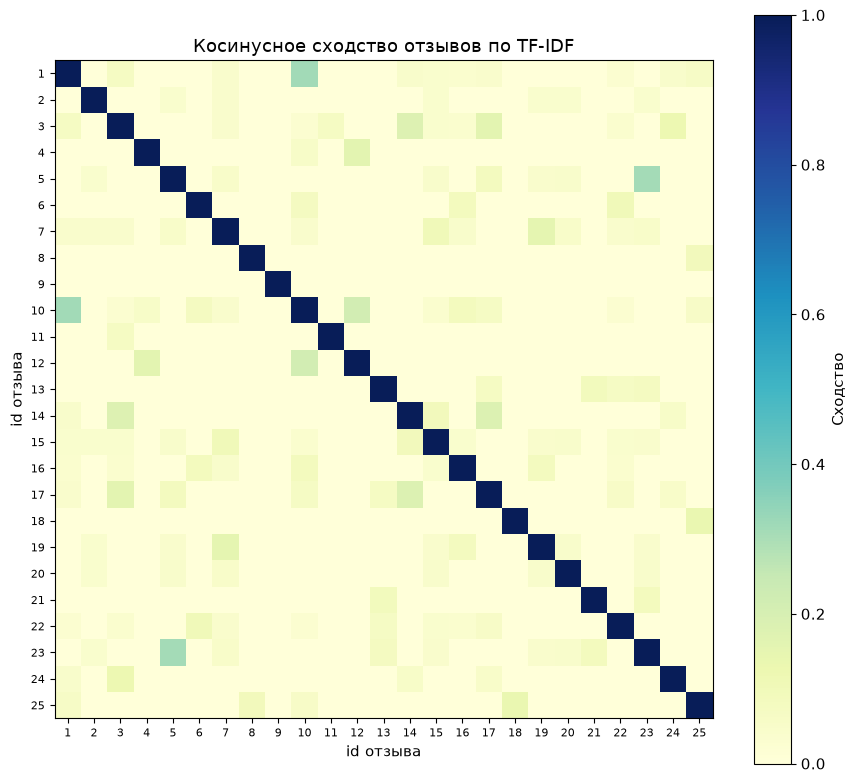

,Тип,Индекс i,Индекс j,id 1,id 2,Сходство
0,Максимум,0,9,1,10,0.3151
1,Вторая похожая пара,4,22,5,23,0.3088
2,Минимум,0,1,1,2,0.0000


Максимум — 0.3151
id 1 : Отличный фильм! Сюжет захватывает с первых минут, актёры играют прекрасно.
id 10 : Слабый фильм, сюжет предсказуем с первых минут. <b>Очень</b> жаль потраченного времени.
Общие леммы без стоп-слов: ['минута', 'первый', 'сюжет', 'фильм']

Вторая похожая пара — 0.3088
id 5 : Замечательная режиссура и красивые пейзажи. Смотрел на https://example.com/trailer — трейлер не обманул!
id 23 : Смотрел трейлер на https://example.com/trailer2 — и разочаровался. Всё интересное было в трейлере.
Общие леммы без стоп-слов: ['смотреть', 'трейлер']

Минимум — 0.0
id 1 : Отличный фильм! Сюжет захватывает с первых минут, актёры играют прекрасно.
id 2 : Скучно и затянуто, еле досмотрел до конца. Больше не буду смотреть такого режиссёра.
Общие леммы без стоп-слов: []

Самый близкий к остальным: индекс 9 , id 10 , среднее сходство 0.0413
Слабый фильм, сюжет предсказуем с первых минут. <b>Очень</b> жаль потраченного времени.
Число пар с нулевым сходством: 229


In [9]:
# Используем TF-IDF из задания 3.3: без стоп-слов, с униграммами и биграммами.
similarity = cosine_similarity(X_tfidf_stop)
display(pd.DataFrame(similarity, index=df['id'], columns=df['id']).round(2))
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(similarity, cmap='YlGnBu', vmin=0, vmax=1)
ax.set_xticks(range(len(df)), labels=df['id'], fontsize=8)
ax.set_yticks(range(len(df)), labels=df['id'], fontsize=8)
ax.set_xlabel('id отзыва')
ax.set_ylabel('id отзыва')
ax.set_title('Косинусное сходство отзывов по TF-IDF')
fig.colorbar(image, ax=ax, label='Сходство')
plt.tight_layout()
plt.show()

# Исключаем диагональ и повторение пар (i, j) и (j, i).
pairs = [(i, j, float(similarity[i, j]))
         for i in range(len(df)) for j in range(i + 1, len(df))]
sorted_pairs = sorted(pairs, key=lambda pair: (-pair[2], pair[0], pair[1]))
most_similar = sorted_pairs[0]
second_similar = sorted_pairs[1]
least_similar = min(pairs, key=lambda pair: pair[2])
pair_table = pd.DataFrame([
    {'Тип': name, 'Индекс i': i, 'Индекс j': j,
     'id 1': int(df.iloc[i]['id']), 'id 2': int(df.iloc[j]['id']), 'Сходство': value}
    for name, (i, j, value) in [('Максимум', most_similar), ('Вторая похожая пара', second_similar), ('Минимум', least_similar)]
])
display(pair_table.round(4))
for name, (i, j, value) in [('Максимум', most_similar), ('Вторая похожая пара', second_similar), ('Минимум', least_similar)]:
    print(name, '—', round(value, 4))
    print('id', df.iloc[i]['id'], ':', df.iloc[i]['text'])
    print('id', df.iloc[j]['id'], ':', df.iloc[j]['text'])
    shared = sorted(set(df.iloc[i]['text_prepared'].split()) & set(df.iloc[j]['text_prepared'].split()) - set(stop_words))
    print('Общие леммы без стоп-слов:', shared)
    print()
mean_similarity = (similarity.sum(axis=1) - np.diag(similarity)) / (len(df) - 1)
central_index = int(mean_similarity.argmax())
print('Самый близкий к остальным: индекс', central_index,
      ', id', df.iloc[central_index]['id'], ', среднее сходство', round(mean_similarity[central_index], 4))
print(df.iloc[central_index]['text'])
print('Число пар с нулевым сходством:', sum(value == 0 for i, j, value in pairs))

Три пары для сравнения:

1. id=1 и id=10: сходство **0.3151**, общие леммы без стоп-слов: «минута», «первый», «сюжет», «фильм».
2. id=5 и id=23: сходство **0.3088**, общие леммы без стоп-слов: «смотреть», «трейлер».
3. id=1 и id=2: сходство **0.0000**, общие леммы без стоп-слов: отсутствуют.

Самая похожая пара имеет общую лексику, а нулевое сходство означает отсутствие общих признаков в выбранном TF-IDF-словаре. Минимум может достигаться несколькими парами: приведена первая по порядку индексов. Векторы не учитывают полноценный контекст, поэтому противоположные по оценке отзывы тоже могут оказаться похожими.

Документ **id=10 (индекс 9)** имеет наибольшее среднее сходство с другими — **0.0413**. Самосходство на диагонали исключено. Этот результат означает лексическую типичность для данного корпуса, а не качество фильма. Числа относятся к варианту 3.3; с другим словарём или сохранением отрицаний результат может отличаться.

## Задание 6.1*. Бонус: лемматизация и стемминг

In [10]:
stemmer = SnowballStemmer('russian')
words = sorted(set(' '.join(df['text_clean']).split()))
comparison = pd.DataFrame({
    'Слово': words,
    'Лемма': [morph.parse(word)[0].normal_form for word in words],
    'Стем': [stemmer.stem(word) for word in words]
})
differences = comparison[comparison['Лемма'] != comparison['Стем']]
print('Форм с различными результатами:', len(differences), 'из', len(comparison))
display(differences.head(15))
print('Уникальных лемм:', comparison['Лемма'].nunique())
print('Уникальных стемов:', comparison['Стем'].nunique())

Форм с различными результатами: 143 из 186


,Слово,Лемма,Стем
0,актёров,актёр,актер
1,актёрского,актёрский,актерск
2,актёры,актёр,актер
4,больше,большой,больш
5,большего,больший,больш
7,буду,быть,буд
9,был,быть,был
10,было,быть,был
12,великолепно,великолепно,великолепн
13,видел,видеть,видел


Уникальных лемм: 161
Уникальных стемов: 167


Лемматизация выбирает словарную начальную форму, а стемминг обрезает окончания по правилам. Например, «актёры» превращается в «актёр» при лемматизации и в «актер» при Snowball-стемминге; остальные реальные примеры приведены в таблице. Стем может быть обрезанным фрагментом, его труднее интерпретировать. Равенство или различие числа уникальных форм не доказывает качество: методы могут по-разному объединять слова. Для читаемого разведочного анализа выбираю леммы.

## Задание 5. Итоговые выводы

1. Исследован корпус из **25** непустых отзывов о фильмах.
2. Очистка удалила ссылки, HTML-теги, хэштеги, цифры и пунктуацию; `<b>Очень</b>` превратилось в слово «очень».
3. Словарь уникальных русских слов изменился с **188** до **186** после очистки и до **161** после лемматизации.
4. Лемматизация уменьшила очищенный словарь на **13.4%**, объединив формы вроде «фильма» и «фильмов» в «фильм».
5. Добавление биграмм увеличило размерность мешка слов с **156** до **372** признаков, позволяя учитывать соседние слова.
6. После min_df=2 и max_df=0.9 осталось **44** униграмм и **49** признаков с биграммами.
7. Мешок слов хранит количества, а TF-IDF выделяет относительно характерные для документа признаки; стоп-слова нужно выбирать осторожно, чтобы не потерять отрицания.
8. Средняя длина отзыва равна **10.60** слов, минимум — **5**, максимум — **17**, число выбросов по длине — **6**.
9. Наибольшее сходство получено у id=1 и id=10 (**0.3151**), а самым типичным по средней близости оказался id=10 (**0.0413**).
10. Для корпуса в 100 раз больше, то есть 2500 отзывов, подходят те же разреженные Count/TF-IDF-матрицы, кэширование лемм и фильтры словаря; полное сравнение пар растёт квадратично, а для дальнейшего роста можно считать ближайших соседей порциями или использовать поисковый индекс.